In [1]:
from __future__ import annotations

import json
import math
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from IPython.display import display, Image

In [2]:
DATA_DIR_NAMES = [
    'upcoding_v28_top10_ha2025_export',
]
DATA_ZIP_NAMES = [f'{name}.zip' for name in DATA_DIR_NAMES]
COEFF_NAME = 'cms_v28_cna_coefficients_export_features.csv'
SEARCH_ROOTS = []
for root in (
    Path.cwd(),
    Path.cwd() / 'data' / 'upcoding',
    Path.cwd().parent / 'data' / 'upcoding',
    Path('/content'),
    Path('/content/data/upcoding'),
):
    if root not in SEARCH_ROOTS and root.exists():
        SEARCH_ROOTS.append(root)

outputs_dir = Path("outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)
OUT = outputs_dir / 'full_alpha_curves_outputs'
FIG = OUT / 'figures'
DATA_OUT = OUT / 'data'
for p in (OUT, FIG, DATA_OUT):
    p.mkdir(parents=True, exist_ok=True)

In [3]:
TAU = 0.5
RHO = 0.5
RELATED_SCORE = 0.5
SIGNAL_MODERATION = 0.25
FLOOR = 0.03
ETA = 1e-6
K_POLICY = 25
LAMBDAS = np.array([1e-6, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0])
ALPHAS = np.array([0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5])

SIGNAL_MODERATED = ['hcc155', 'hcc280', 'hcc38', 'hcc93', 'hcc328', 'hcc226']
RELATED_EXTRA = ['hcc21', 'hcc23', 'hcc35', 'hcc62', 'hcc64', 'hcc264', 'hcc267', 'hcc327']
MANUAL_BLOCKS = [
    ('Diabetes model branch', ['hcc36', 'hcc37', 'hcc38']),
    ('Heart failure model branch', ['hcc224', 'hcc225', 'hcc226']),
    ('CKD model branch', ['hcc328', 'hcc329']),
    ('Substance-use model branch', ['hcc137', 'hcc138', 'hcc139']),
    ('Mental-health model branch', ['hcc151', 'hcc152', 'hcc153', 'hcc154', 'hcc155']),
    ('Vascular disease model branch', ['hcc263', 'hcc264', 'hcc267']),
    ('Cancer model branch', ['hcc20', 'hcc21', 'hcc22', 'hcc23']),
]

MAIN_COLORS = {
    'Proposed subset-ridge': '#009E73',
    'Full ridge': '#666666',
    'Top-10 exclusion': '#E69F00',
    'Cost-only ridge': '#56B4E9',
    'Prediction-only ridge': '#CC79A7',
    'Subset only': '#7E57C2',
    'Oracle': '#111111',
    'OLS': '#7f7f7f',
}

plt.rcParams.update({
    'font.size': 8.8,
    'axes.titlesize': 9.6,
    'axes.labelsize': 10.0,
    'xtick.labelsize': 8.0,
    'ytick.labelsize': 8.0,
    'legend.fontsize': 7.6,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 240,
    'savefig.dpi': 350,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})


In [6]:
# Helper functions
def resolve_data_dir() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        for name in DATA_DIR_NAMES:
            candidate = root / name
            searched.append(str(candidate))
            if (candidate / 'baseline_hier.csv').exists():
                return candidate
    for root in SEARCH_ROOTS:
        for name in DATA_ZIP_NAMES:
            zip_path = root / name
            searched.append(str(zip_path))
            if zip_path.exists():
                work = OUT / '_unzipped'
                if work.exists():
                    shutil.rmtree(work)
                work.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(zip_path) as z:
                    z.extractall(work)
                for candidate in work.rglob('baseline_hier.csv'):
                    return candidate.parent
    raise FileNotFoundError(
        'Could not find the upcoding export folder or zip. Searched: ' + ', '.join(searched)
    )

def resolve_coeff_path() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        candidate = root / COEFF_NAME
        searched.append(str(candidate))
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        'Could not find the coefficient CSV. Searched: ' + ', '.join(searched)
    )

def parse_group_hccs(s) -> list[str]:
    if pd.isna(s):
        return []
    s = str(s).replace('HCC', 'hcc').replace(' ', '')
    return [p for p in s.split(',') if p.startswith('hcc')]

def get_target_rows(target_map: pd.DataFrame, features_all: list[str], coeff: pd.DataFrame) -> pd.DataFrame:
    rows = []
    if {'diagnosis_group', 'health_affairs_group_hccs', 'removal_effect_percent'}.issubset(target_map.columns):
        raw = target_map['removal_effect_percent'].astype(float).to_numpy()
        denom = float(np.nanmax(raw)) if np.nanmax(raw) > 0 else 1.0
        for _, r in target_map.iterrows():
            members = parse_group_hccs(r.get('health_affairs_group_hccs', ''))
            if not members:
                members = [str(r.get('target_hcc', r.get('hcc', '')))]
            rows.append({
                'diagnosis_group': str(r['diagnosis_group']),
                'members': members,
                'target_hcc': str(r.get('target_hcc', members[0] if members else '')),
                'score_raw': float(r['removal_effect_percent']),
                'score': float(r['removal_effect_percent']) / denom,
                'source': 'health-affairs-risk-contribution',
            })
        return pd.DataFrame(rows)
    if {'v22_label', 'hcc', 'ma_prev', 'tm_prev'}.issubset(target_map.columns):
        tmp = target_map.copy()
        tmp['lift_weight'] = tmp.get('lift_weight', 1.0)
        raw_scores = []
        for _, r in tmp.iterrows():
            h = str(r['hcc'])
            coef = float(coeff.loc[h, 'cna_coef']) if h in coeff.index else 1.0
            raw_scores.append(max(float(r['ma_prev']) - float(r['tm_prev']), 0.0) * float(r['lift_weight']) * abs(coef))
        denom = max(raw_scores) if max(raw_scores) > 0 else 1.0
        for raw, (_, r) in zip(raw_scores, tmp.iterrows()):
            h = str(r['hcc'])
            rows.append({
                'diagnosis_group': str(r['v22_label']),
                'members': [h],
                'target_hcc': h,
                'score_raw': raw,
                'score': raw / denom,
                'source': 'ma-tm-prevalence-lift-times-signal',
            })
        return pd.DataFrame(rows)
    raise ValueError('Unrecognized target mapping table format.')

def support_to_string(features: list[str], support) -> str:
    return '|'.join(features[i] for i in sorted(support))

def parse_support(s: object) -> set[str]:
    if pd.isna(s):
        return set()
    if isinstance(s, str):
        return {x for x in s.split('|') if x}
    return set(s)

Using data directory: outputs/full_alpha_curves_outputs/_unzipped/content/upcoding_v28_top10_ha2025_export
{
  "active_hcc_count": 30,
  "tau": 0.5,
  "rho": 0.5,
  "k_policy": 25,
  "alphas": [
    0.0,
    0.25,
    0.5,
    0.75,
    1.0,
    1.25,
    1.5
  ],
  "figure_pdf": "outputs/full_alpha_curves_outputs/figures/full_alpha_curves.pdf",
  "figure_png": "outputs/full_alpha_curves_outputs/figures/full_alpha_curves.png",
  "normalized_figure_pdf": "outputs/full_alpha_curves_outputs/figures/full_alpha_curves_normalized.pdf",
  "normalized_figure_png": "outputs/full_alpha_curves_outputs/figures/full_alpha_curves_normalized.png"
}
Wrote figure files to: /mnt/nfs/CX900004_DS17/strategic-feature-selection/notebooks/outputs/full_alpha_curves_outputs/figures


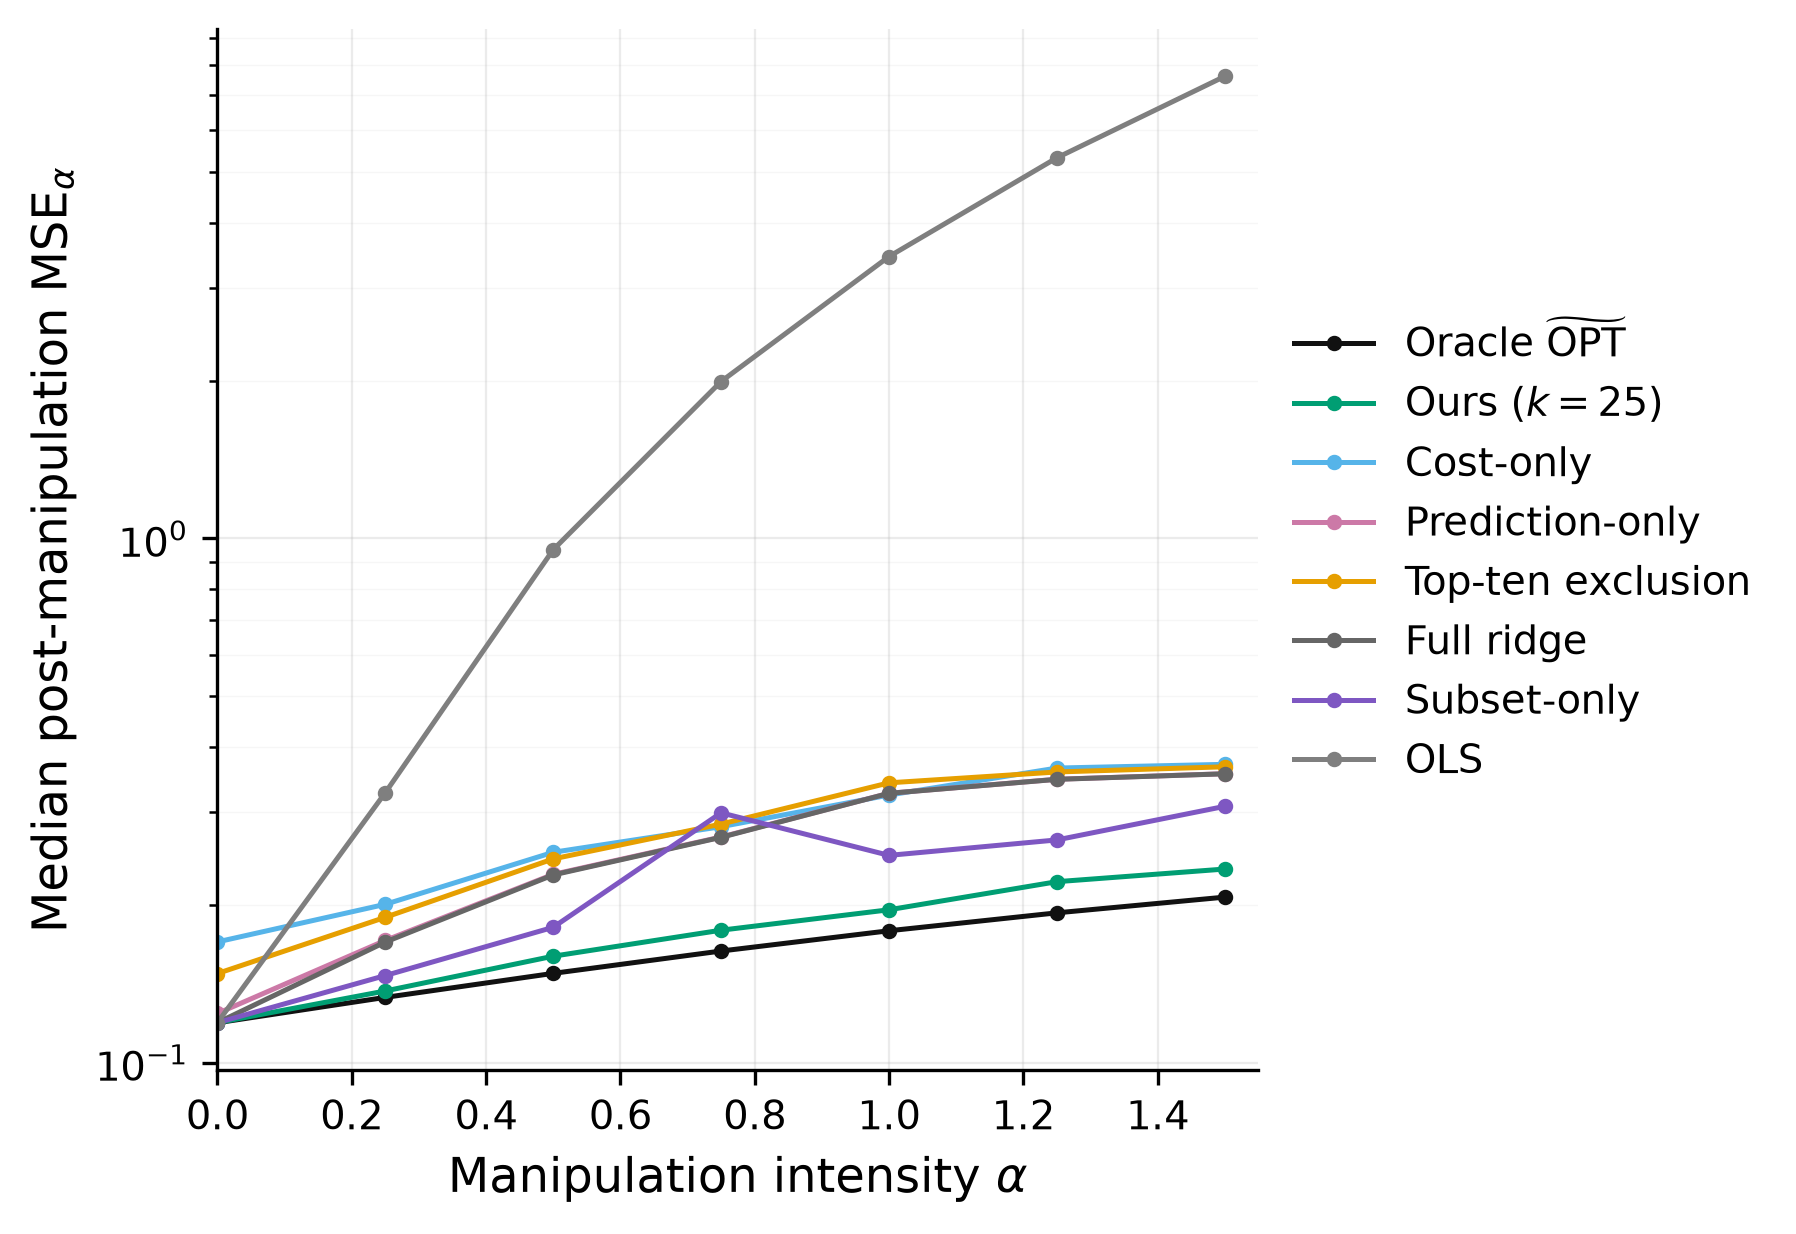

In [7]:
class CaseStudyProblem:
    def __init__(self, data_dir: Path):
        self.data_dir = data_dir
        self.base = pd.read_csv(data_dir / 'baseline_hier.csv')
        self.target_map = pd.read_csv(data_dir / 'target_mapping_table.csv')
        self.coeff = pd.read_csv(resolve_coeff_path()).set_index('feature')
        self.features_all = [c for c in self.base.columns if c != 'person_id']

        X_all_raw = self.base[self.features_all].astype(float).values
        self.prev_all = X_all_raw.mean(axis=0)
        self.active_idx = np.where(self.prev_all > 0)[0]
        self.features = [self.features_all[i] for i in self.active_idx]
        self.d = len(self.features)

        theta_all = np.zeros(len(self.features_all))
        self.desc_map = {f: '' for f in self.features_all}
        for i, f in enumerate(self.features_all):
            if f in self.coeff.index:
                theta_all[i] = float(self.coeff.loc[f, 'cna_coef'])
                self.desc_map[f] = str(self.coeff.loc[f, 'description'])
        self.theta = theta_all[self.active_idx]

        X = X_all_raw[:, self.active_idx]
        self.X_centered = X - X.mean(axis=0)
        self.Sigma = (self.X_centered.T @ self.X_centered) / self.X_centered.shape[0]
        self.Sigma = (self.Sigma + self.Sigma.T) / 2
        self.bvec = self.Sigma @ self.theta
        signal = self.X_centered @ self.theta
        self.sigma2 = float(0.25 * np.var(signal))
        self._support_risk_cache = {}
        self.build_cost_matrix()

    def build_cost_matrix(self):
        target_rows = get_target_rows(self.target_map, self.features_all, self.coeff)
        D_raw_all = np.full(len(self.features_all), FLOOR)
        group_blocks = []
        self.top_members = set()
        self.top_group = {}
        self.top_score = {}

        for _, row in target_rows.iterrows():
            score = float(row['score'])
            members = [m for m in row['members'] if isinstance(m, str) and m in self.features_all]
            group_name = str(row['diagnosis_group'])
            if members:
                group_blocks.append((group_name, members))
            for f in members:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + score)
                self.top_members.add(f)
                self.top_group[f] = group_name
                self.top_score[f] = score

        for f in RELATED_EXTRA:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + RELATED_SCORE)

        D_final_all = D_raw_all.copy()
        for f in SIGNAL_MODERATED:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_final_all[j] = FLOOR + SIGNAL_MODERATION * (D_final_all[j] - FLOOR)

        block_defs = group_blocks + MANUAL_BLOCKS
        seen, block_defs_unique = set(), []
        for name, members in block_defs:
            key = tuple(sorted(members))
            if key in seen:
                continue
            seen.add(key)
            block_defs_unique.append((name, members))

        B_all = np.zeros((len(self.features_all), len(self.features_all)))
        for _, members in block_defs_unique:
            idx = [self.features_all.index(f) for f in members if f in self.features_all]
            if len(idx) >= 2:
                v = np.zeros(len(self.features_all))
                for j in idx:
                    v[j] = math.sqrt(max(D_final_all[j], FLOOR))
                B_all += np.outer(v, v)

        self.D_all = D_final_all
        self.B_all = B_all
        self.D = D_final_all[self.active_idx]
        self.B = B_all[np.ix_(self.active_idx, self.active_idx)]
        if np.max(np.diag(self.B)) > 0:
            self.B = self.B / np.max(np.diag(self.B))
        self.G = TAU * (np.diag(self.D) + RHO * self.B) + ETA * np.eye(self.d)
        self.H = np.linalg.inv(self.G)

        comp_rows = []
        for pos, f in enumerate(self.features):
            category = 'baseline floor'
            if f in RELATED_EXTRA and f not in self.top_members:
                category = 'pre-specified diagonal score'
            if f in self.top_members:
                category = 'coding-sensitive group score'
            if f in SIGNAL_MODERATED:
                category = 'signal-moderated top-ten groups'
            j = self.features_all.index(f);
            comp_rows.append({
                'feature': f,
                'description': self.desc_map.get(f, ''),
                'baseline_prevalence': float(self.prev_all[j]),
                'theta_star': float(self.theta[pos]),
                'abs_theta_star': abs(float(self.theta[pos])),
                'top10_group': self.top_group.get(f, ''),
                'coding_sensitive': f in self.top_members,
                'group_score': float(self.top_score.get(f, np.nan)) if f in self.top_score else np.nan,
                'D_final': float(self.D[pos]),
                'B_diag': float(self.B[pos, pos]),
                'Hinv_diag': float(self.G[pos, pos]),
                'category': category,
                'signal_moderated': f in SIGNAL_MODERATED,
                'related_diagonal': f in RELATED_EXTRA,
                'active': True,
            })
        self.component_df = pd.DataFrame(comp_rows)

    def support_beta(self, S, lam: float):
        beta = np.zeros(self.d)
        idx = np.array(sorted(set(S)), dtype=int)
        if len(idx) == 0:
            return beta
        A = self.Sigma[np.ix_(idx, idx)] + lam * np.eye(len(idx))
        rhs = self.Sigma[np.ix_(idx, np.arange(self.d))] @ self.theta
        beta[idx] = np.linalg.solve(A + 1e-10 * np.eye(len(idx)), rhs)
        return beta

    def support_mask(self, S) -> int:
        mask = 0
        for i in sorted(set(S)):
            mask |= 1 << int(i)
        return mask

    def support_from_mask(self, mask: int) -> tuple[int, ...]:
        return tuple(i for i in range(self.d) if mask & (1 << i))

    def support_risk(self, S, lam: float, alpha: float = 1.0) -> float:
        mask = self.support_mask(S)
        key = (mask, float(lam), float(alpha))
        val = self._support_risk_cache.get(key)
        if val is not None:
            return val
        beta = self.support_beta(self.support_from_mask(mask), lam)
        val = self.mse(beta, alpha)
        self._support_risk_cache[key] = val
        return val

    def full_beta(self, lam: float):
        try:
            return np.linalg.solve(self.Sigma + lam * np.eye(self.d), self.bvec)
        except np.linalg.LinAlgError:
            return np.linalg.lstsq(self.Sigma + 1e-8 * np.eye(self.d), self.bvec, rcond=None)[0]

    def mse(self, beta, alpha: float = 1.0):
        diff = beta - self.theta
        pred = float(diff @ self.Sigma @ diff)
        q = float(beta @ self.G @ beta)
        return pred + (alpha * q) ** 2 + self.sigma2

    def full_ols_beta(self):
        return np.linalg.pinv(self.Sigma, rcond=1e-10) @ self.bvec

    def full_ols(self, alpha: float = 1.0):
        beta = self.full_ols_beta()
        val = self.mse(beta, alpha)
        return {'mse': val, 'risk': val, 'lambda': 0.0, 'beta': beta, 'support': tuple(range(self.d))}

    def tune_full(self, alpha: float = 1.0):
        best = None
        for lam in LAMBDAS:
            beta = self.full_beta(lam)
            val = self.mse(beta, alpha)
            if best is None or val < best['mse']:
                best = {'mse': val, 'risk': val, 'lambda': float(lam), 'beta': beta, 'support': tuple(range(self.d))}
        return best

    def tune_support(self, S, alpha: float = 1.0, lambdas=LAMBDAS):
        best = None
        for lam in lambdas:
            val = self.support_risk(S, lam, alpha)
            if best is None or val < best['mse']:
                beta = self.support_beta(S, lam)
                best = {'mse': val, 'risk': val, 'lambda': float(lam), 'beta': beta, 'support': tuple(sorted(S))}
        return best

    def oracle(self, alpha: float = 1.0):
        if alpha == 0:
            val = self.mse(self.theta, 0.0);
            return {'mse': val, 'risk': val, 'beta': self.theta.copy(), 'gamma': 0.0, 'support': tuple(range(self.d))}

        def beta_given_gamma(gamma):
            return np.linalg.solve(self.Sigma + gamma * self.G + 1e-10 * np.eye(self.d), self.bvec)

        def fixed_point(gamma):
            beta = beta_given_gamma(gamma)
            return gamma - 2 * alpha * alpha * float(beta @ self.G @ beta)

        hi = 1.0
        while fixed_point(hi) < 0 and hi < 1e12:
            hi *= 2
        gamma = brentq(fixed_point, 0, hi) if hi < 1e12 else hi
        beta = beta_given_gamma(gamma)
        val = self.mse(beta, alpha)
        return {'mse': val, 'risk': val, 'beta': beta, 'gamma': float(gamma), 'support': tuple(range(self.d))}

    def swap_local_exact_k(self, S0, lam: float, k: int, alpha: float = 1.0, max_iter: int = 100):
        S = set(S0)
        if len(S) != k:
            raise ValueError('Initial support must have exact cardinality k')
        cur = self.support_risk(S, lam, alpha)
        for _ in range(max_iter):
            best, move = cur, None
            for i in list(S):
                base = S - {i}
                for j in range(self.d):
                    if j in S:
                        continue
                    val = self.support_risk(base | {j}, lam, alpha)
                    if val < best - 1e-12:
                        best, move = val, (i, j)
            if move is None:
                break
            S.remove(move[0])
            S.add(move[1])
            cur = best
        beta = self.support_beta(S, lam)
        val = self.mse(beta, alpha)
        return {'mse': val, 'risk': val, 'lambda': float(lam), 'beta': beta, 'support': tuple(sorted(S))}

    def greedy_exact_k(self, k: int, lam: float, alpha: float = 1.0):
        S = set()
        while len(S) < k:
            best, best_j = None, None
            for j in range(self.d):
                if j in S:
                    continue
                val = self.support_risk(S | {j}, lam, alpha)
                if best is None or val < best:
                    best, best_j = val, j
            S.add(best_j)
        return self.swap_local_exact_k(S, lam, k, alpha)

    def tune_exact_k(self, k: int, alpha: float = 1.0):
        best = None
        for lam in LAMBDAS:
            rec = self.greedy_exact_k(k, lam, alpha)
            if best is None or rec['mse'] < best['mse']:
                best = rec
        return best

    def exact_k_frontier(self, alpha: float = 1.0):
        rows = []
        for k in range(1, self.d + 1):
            rec = self.tune_exact_k(k, alpha);
            rows.append({
                'k': k,
                'risk': float(rec['mse']),
                'mse': float(rec['mse']),
                'lambda': float(rec['lambda']),
                'support': support_to_string(self.features, rec['support']),
            })
        df = pd.DataFrame(rows)
        full = float(df.loc[df['k'].eq(self.d), 'risk'].iloc[0])
        df['risk_rel_full'] = df['risk'] / full
        df['gain_vs_full'] = 1.0 - df['risk_rel_full']
        return df[['k', 'risk', 'risk_rel_full', 'gain_vs_full', 'lambda', 'support']]

    def alpha_curves(self):
        idx_top = {i for i, f in enumerate(self.features) if f in self.top_members}
        S_exclude = tuple(i for i in range(self.d) if i not in idx_top)
        S_cost = tuple(sorted(np.argsort(np.diag(self.G))[:K_POLICY].tolist()))
        S_pred = tuple(sorted(np.argsort(-np.abs(self.bvec))[:K_POLICY].tolist()))

        records = []
        method_order = [
            'Oracle',
            'Proposed subset-ridge',
            'Subset only',
            'Cost-only ridge',
            'Prediction-only ridge',
            'Top-10 exclusion',
            'Full ridge',
            'OLS',
        ]
        for alpha in ALPHAS:
            full = self.tune_full(alpha)
            full_mse = full['mse']
            prop = self.tune_exact_k(K_POLICY, alpha)
            subset_beta = self.support_beta(prop['support'], 0.0)
            subset_mse = self.mse(subset_beta, alpha)
            recs = {
                'Oracle': self.oracle(alpha),
                'Proposed subset-ridge': prop,
                'Subset only': {'mse': subset_mse, 'risk': subset_mse, 'lambda': 0.0, 'beta': subset_beta, 'support': prop['support']},
                'Cost-only ridge': self.tune_support(S_cost, alpha),
                'Prediction-only ridge': self.tune_support(S_pred, alpha),
                'Top-10 exclusion': self.tune_support(S_exclude, alpha),
                'Full ridge': full,
                'OLS': self.full_ols(alpha),
            }
            for method in method_order:
                rec = recs[method]
                records.append({
                    'alpha': float(alpha),
                    'method': method,
                    'mse': float(rec['mse']),
                    'mse_rel_full': float(rec['mse'] / full_mse),
                    'rmse': float(math.sqrt(rec['mse'])),
                    'rmse_rel_full': float(math.sqrt(rec['mse'] / full_mse)),
                    'support_size': len(rec.get('support', ())),
                    'lambda': rec.get('lambda', np.nan),
                    'support': support_to_string(self.features, rec.get('support', ())),
                })
        return pd.DataFrame(records)


# Plotting
def plot_figS1_full_alpha_curves(alpha_df: pd.DataFrame, normalize_by_full_ridge: bool = False):
    """Plot all-baseline alpha curves."""
    df = alpha_df.copy()
    df['endogenous_rmse'] = np.sqrt(df['mse'])

    curves = (
        df.groupby(['alpha', 'method'], as_index=False)
          .agg(strategic_mse=('mse', 'median'), endogenous_rmse=('endogenous_rmse', 'median'))
    )

    if normalize_by_full_ridge:
        full = curves[curves['method'].eq('Full ridge')][['alpha', 'strategic_mse', 'endogenous_rmse']].copy()
        full = full.rename(columns={
            'strategic_mse': 'full_strategic_mse',
            'endogenous_rmse': 'full_endogenous_rmse',
        })
        curves = curves.merge(full, on='alpha', how='left')
        curves['strategic_mse'] = curves['strategic_mse'] / curves['full_strategic_mse']
        curves['endogenous_rmse'] = curves['endogenous_rmse'] / curves['full_endogenous_rmse']

    method_order = [
        'Oracle',
        'Proposed subset-ridge',
        'Cost-only ridge',
        'Prediction-only ridge',
        'Top-10 exclusion',
        'Full ridge',
        'Subset only',
        'OLS',
    ]
    method_order = [m for m in method_order if m in set(curves['method'])]

    label = {
        'Oracle': r'Oracle $\widetilde{\mathrm{OPT}}$',
        'Proposed subset-ridge': f'Ours ($k={K_POLICY}$)',
        'Cost-only ridge': 'Cost-only',
        'Prediction-only ridge': 'Prediction-only',
        'Top-10 exclusion': 'Top-ten exclusion',
        'Full ridge': 'Full ridge',
        'Subset only': 'Subset-only',
        'OLS': 'OLS',
    }

    plt.rcParams.update({
        'font.size': 10.0,
        'axes.titlesize': 11.0,
        'axes.labelsize': 11.5,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 9.5,
        'figure.dpi': 220,
        'savefig.dpi': 350,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'lines.linewidth': 1.35,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    })

    fig, ax = plt.subplots(1, 1, figsize=(6.5, 4), constrained_layout=True)
    ax.set_box_aspect(1)
    for method in method_order:
        sub = curves[curves['method'].eq(method)].sort_values('alpha')
        if sub.empty:
            continue
        color = MAIN_COLORS.get(method, '#333333')
        ax.plot(sub['alpha'], sub['strategic_mse'], marker='o', ms=2.7, lw=1.20,
                     color=color, label=label[method]) # Only plot strategic_mse

    ax.set_xlim(0, 1.55) # Extended to 1.55 to avoid cutting off points at 1.5
    ax.set_yscale('log')
    ax.set_xlabel(r'Manipulation intensity $\alpha$')
    ax.grid(True, which='major', alpha=0.25, linewidth=0.55)
    ax.grid(True, which='minor', alpha=0.10, linewidth=0.35)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    if normalize_by_full_ridge:
        ax.set_ylabel('Strategic MSE / full ridge')
        stem = 'full_alpha_curves_normalized'
    else:
        ax.set_ylabel(r'Median post-manipulation $\mathrm{MSE}_\alpha$')
        stem = 'full_alpha_curves'

    # Move legend to the side of the single plot
    ax.legend(frameon=False, ncol=1, loc='center left', bbox_to_anchor=(1, 0.5))

    for ext in ['pdf', 'png']:
        fig.savefig(FIG / f'{stem}.{ext}', dpi=300, bbox_inches='tight')
    plt.close(fig)

    curves.to_csv(DATA_OUT / f'{stem}_plotted_values.csv', index=False)
    return FIG / f'{stem}.pdf', FIG / f'{stem}.png'


def main():
    data_dir = resolve_data_dir()
    print(f'Using data directory: {data_dir}')
    resolve_coeff_path()

    problem = CaseStudyProblem(data_dir)
    alpha_df = problem.alpha_curves()
    alpha_df.to_csv(DATA_OUT / 'alpha_curves_tau05_k25_with_ols.csv', index=False)

    out_pdf, out_png = plot_figS1_full_alpha_curves(alpha_df, normalize_by_full_ridge=False)
    norm_pdf, norm_png = plot_figS1_full_alpha_curves(alpha_df, normalize_by_full_ridge=True)

    summary = {
        'active_hcc_count': len(problem.features),
        'tau': TAU,
        'rho': RHO,
        'k_policy': K_POLICY,
        'alphas': [float(a) for a in ALPHAS],
        'figure_pdf': str(out_pdf),
        'figure_png': str(out_png),
        'normalized_figure_pdf': str(norm_pdf),
        'normalized_figure_png': str(norm_png),
    }
    (OUT / 'summary.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2))
    print(f'Wrote figure files to: {FIG.resolve()}')

    if display is not None and Image is not None:
        display(Image(filename=str(out_png)))


if __name__ == '__main__':
    main()
